# Statistical Graphics with Seaborn and Plotly

This notebook follows the original analysis sequence. Each step explains the operation being performed; data and computational formulas are retained. Run all cells locally to refresh the saved figures.


## Environment and data


In [1]:
# Load the visualization libraries used in subsequent examples.




import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px

In [2]:
# Load Plotly’s built-in Gapminder dataset as the common input.

df = px.data.gapminder()

In [3]:
# Inspect the dataset before transforming or plotting it.
df

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4
...,...,...,...,...,...,...,...,...
1699,Zimbabwe,Africa,1987,62.351,9216418,706.157306,ZWE,716
1700,Zimbabwe,Africa,1992,60.377,10704340,693.420786,ZWE,716
1701,Zimbabwe,Africa,1997,46.809,11404948,792.449960,ZWE,716
1702,Zimbabwe,Africa,2002,39.989,11926563,672.038623,ZWE,716


In [4]:
# Exclude rows containing missing entries.

df.dropna(inplace=True)

## Pairwise and distribution views


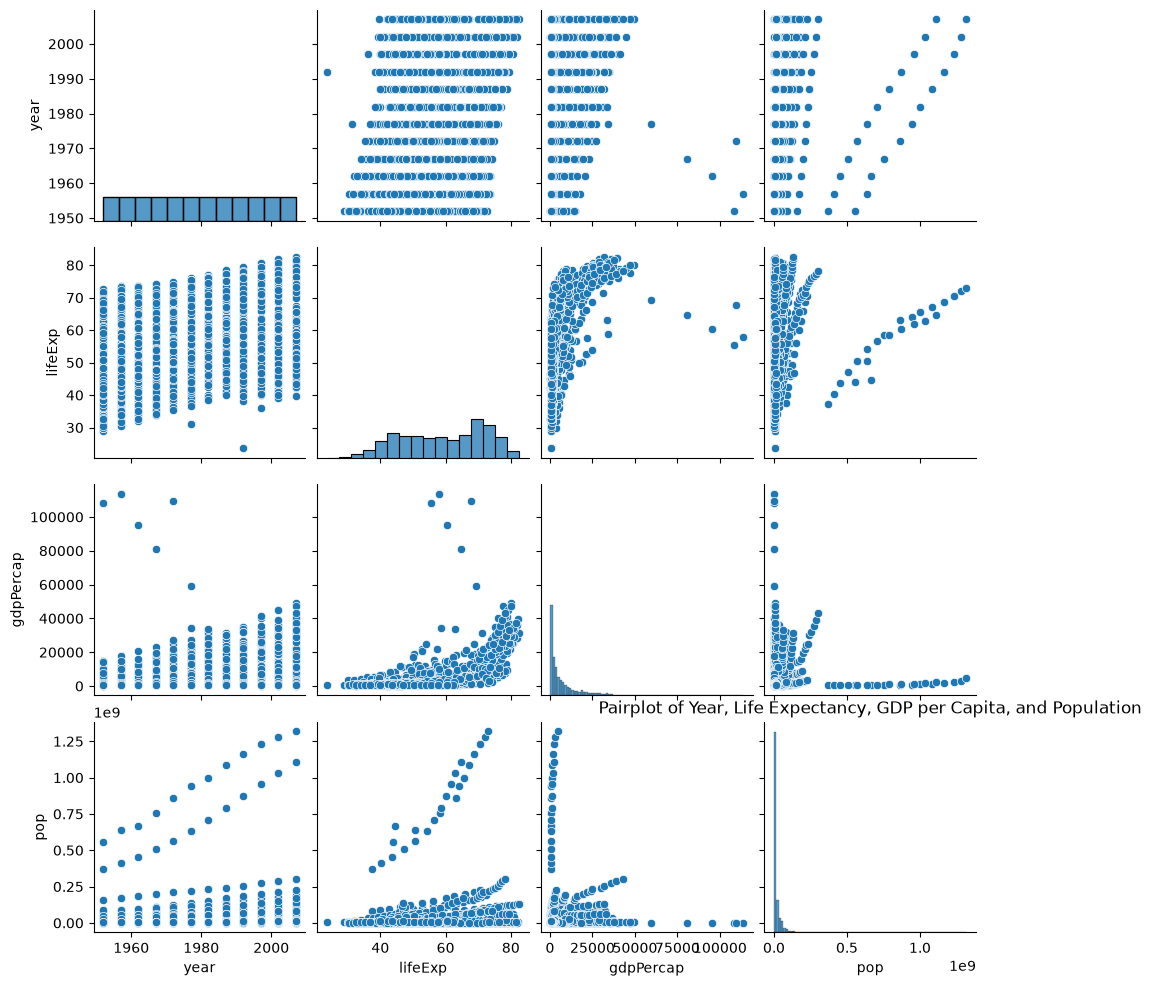

In [5]:
# Compare numeric attributes pairwise.

sns.pairplot(df[['year', 'lifeExp', 'gdpPercap', 'pop']])
plt.title('Pairplot of Year, Life Expectancy, GDP per Capita, and Population')
plt.show()

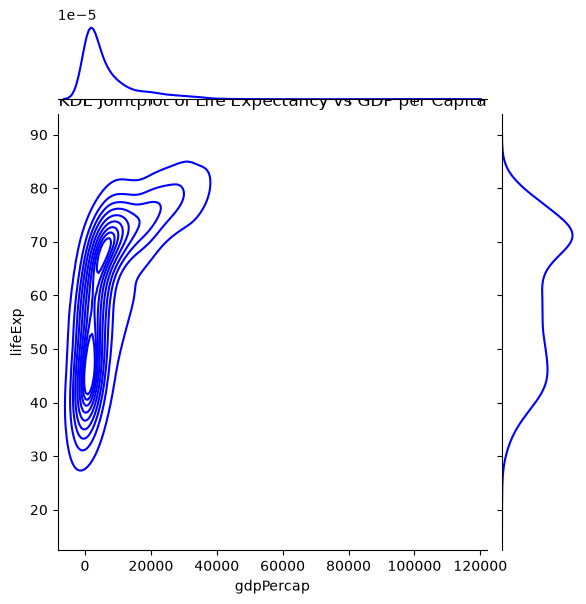

In [6]:
# Inspect the bivariate density of income and life expectancy.

sns.jointplot(x='gdpPercap', y='lifeExp', data=df, kind='kde', color='blue')
plt.title('KDE Jointplot of Life Expectancy vs GDP per Capita')

plt.show()

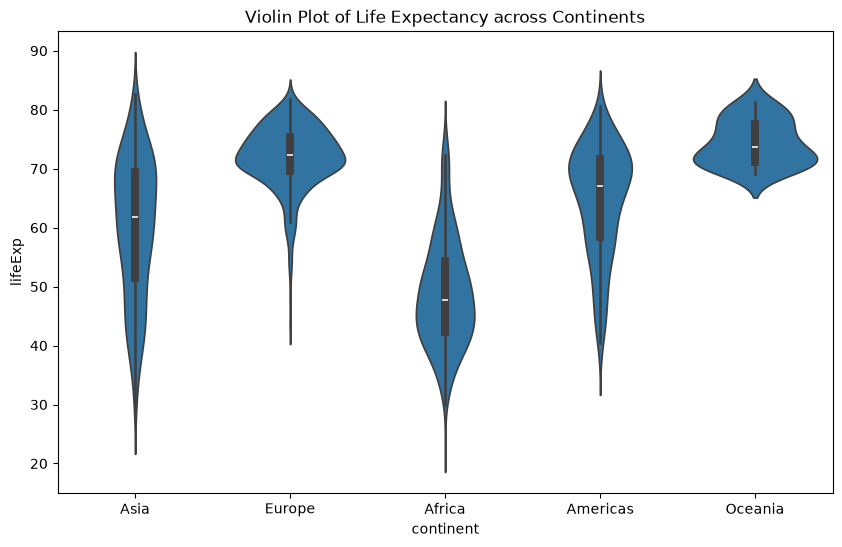

In [7]:
# Compare life-expectancy distributions by continent.

plt.figure(figsize=(10, 6))
sns.violinplot(x='continent', y='lifeExp', data=df)
plt.title('Violin Plot of Life Expectancy across Continents')
plt.show()

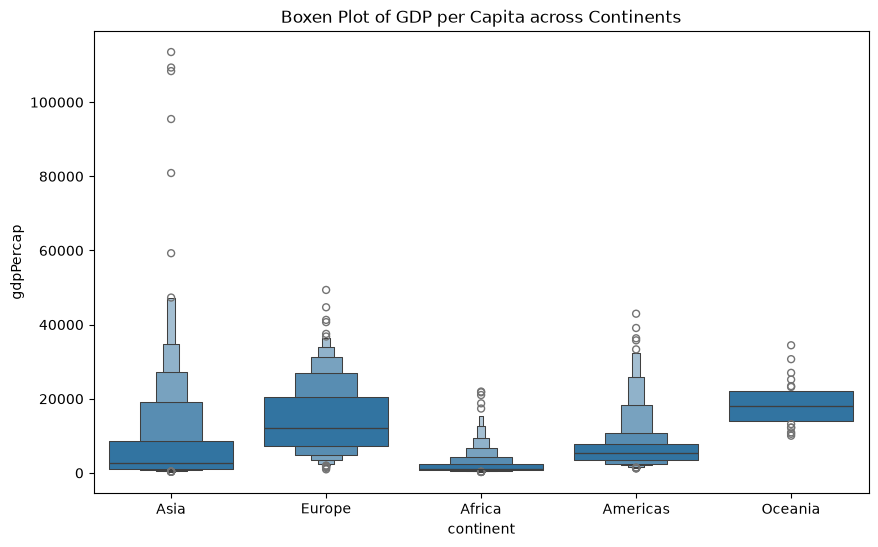

In [8]:
# Inspect GDP per capita with a letter-value plot.

plt.figure(figsize=(10, 6))
sns.boxenplot(x='continent', y='gdpPercap', data=df)
plt.title('Boxen Plot of GDP per Capita across Continents')
plt.show()

/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/seaborn/categorical.py:3399: UserWarning: 5.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/seaborn/categorical.py:3399: UserWarning: 7.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/seaborn/categorical.py:3399: UserWarning: 6.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/seaborn/categorical.py:3

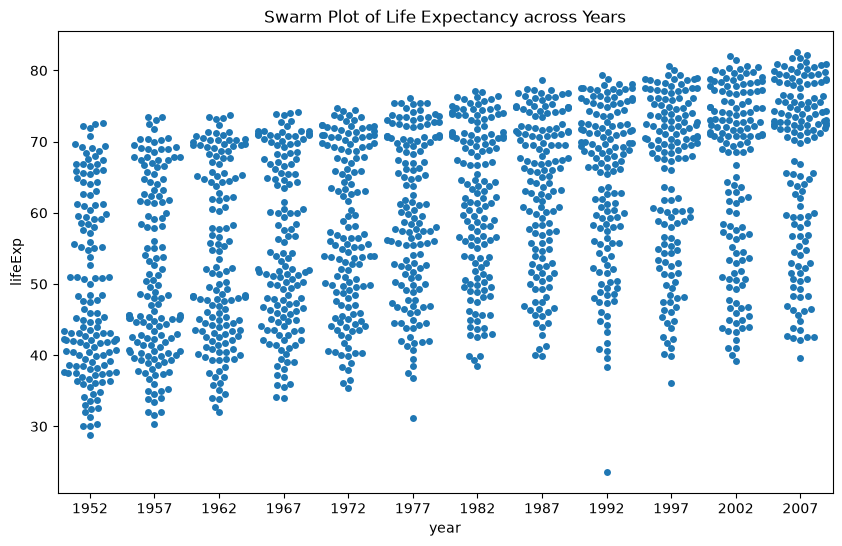

In [9]:
# Compare yearly life expectancy with a swarm plot.

plt.figure(figsize=(10, 6))
sns.swarmplot(x='year', y='lifeExp', data=df)
plt.title('Swarm Plot of Life Expectancy across Years')
plt.show()

In [10]:
# Build an interactive strip plot with country colors.
import plotly.express as px

fig = px.strip(df, x='year', y='lifeExp', color='country', title='Swarm Plot of Life Expectancy across Years')
fig.update_traces(jitter=1)  
fig.show()

## Correlation and faceting


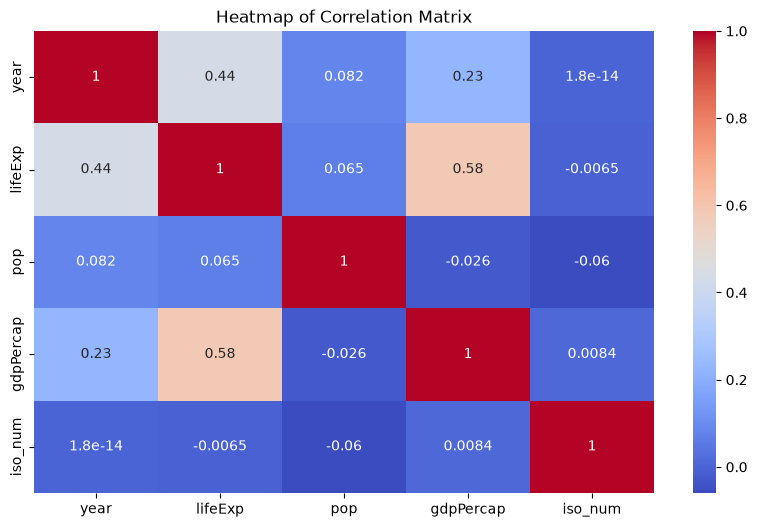

In [11]:
# Summarize correlations among numeric attributes.

plt.figure(figsize=(10, 6))

numerical_df = df.select_dtypes(include=['number'])
sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm')
plt.title('Heatmap of Correlation Matrix')
plt.show()




In [12]:
# Facet income–longevity scatter plots by country.

g = sns.FacetGrid(df, col='country', col_wrap=3)
g.map(sns.scatterplot, 'gdpPercap', 'lifeExp')
g.fig.suptitle('Scatter Plot of Life Expectancy vs GDP per Capita (Faceted by Continent)', y=1.02)
plt.show()

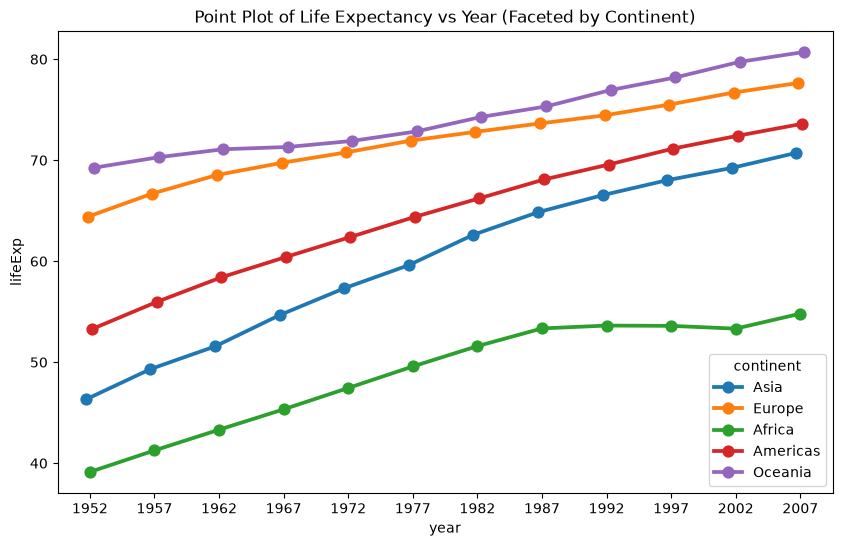

In [13]:
# Compare year-to-year life expectancy across continents.

plt.figure(figsize=(10, 6))
sns.pointplot(x='year', y='lifeExp', hue='continent', data=df, dodge=True, errorbar=None)
plt.title('Point Plot of Life Expectancy vs Year (Faceted by Continent)')
plt.show()

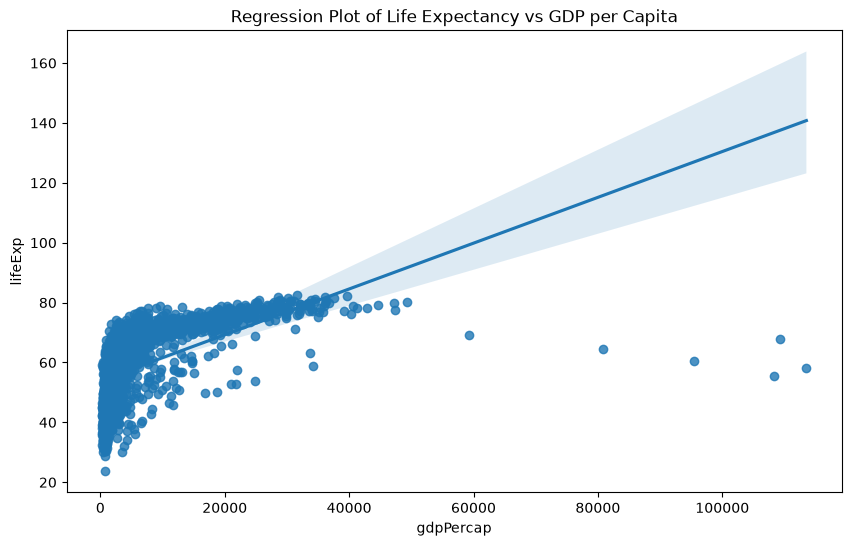

In [14]:
# Fit a simple visual regression trend.

plt.figure(figsize=(10, 6))
sns.regplot(x='gdpPercap', y='lifeExp', data=df)
plt.title('Regression Plot of Life Expectancy vs GDP per Capita')
plt.show()


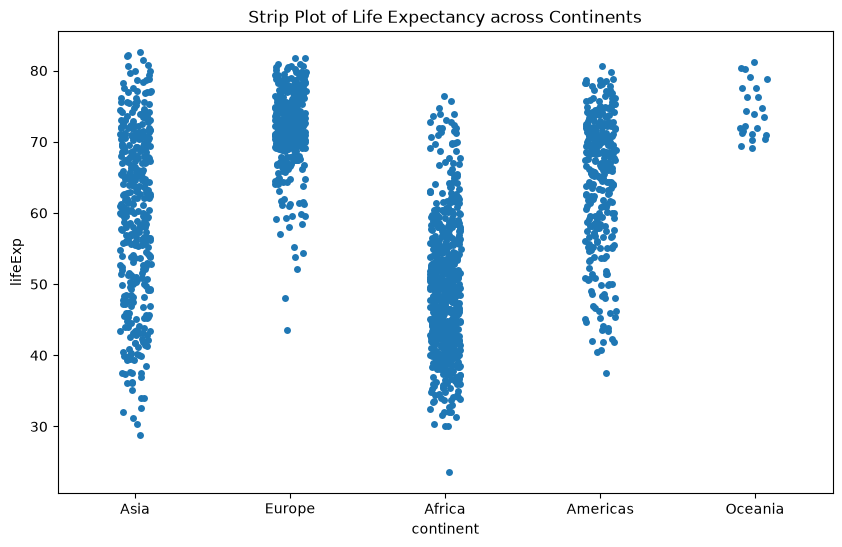

In [15]:
# Explore life expectancy as a categorical strip distribution.

plt.figure(figsize=(10, 6))
sns.stripplot(x='continent', y='lifeExp', data=df)
plt.title('Strip Plot of Life Expectancy across Continents')
plt.show()

## Aggregated and time-oriented charts


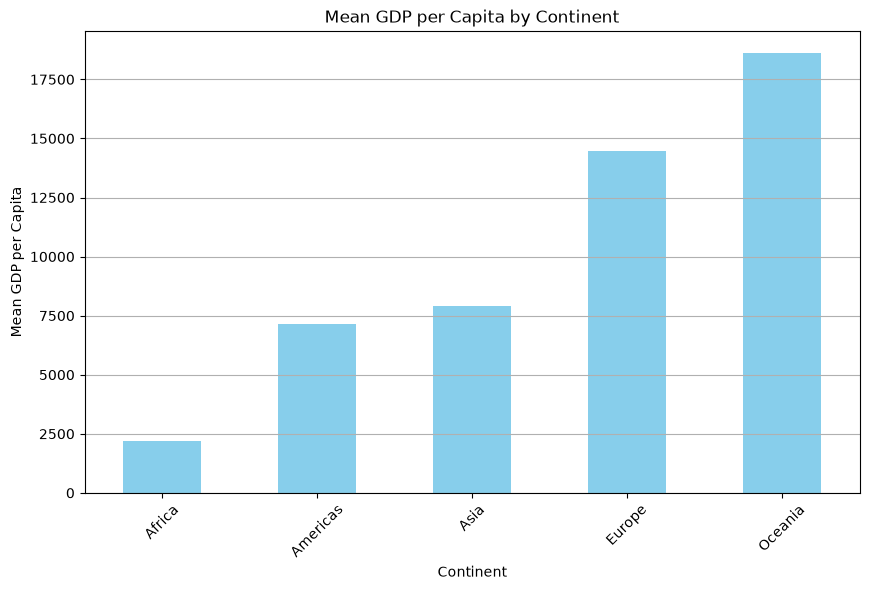

In [16]:
# Compare continent-level average GDP per capita.

import matplotlib.pyplot as plt
import pandas as pd

plt.figure(figsize=(10, 6))
df.groupby('continent')['gdpPercap'].mean().plot(kind='bar', color='skyblue')
plt.title('Mean GDP per Capita by Continent')
plt.xlabel('Continent')
plt.ylabel('Mean GDP per Capita')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

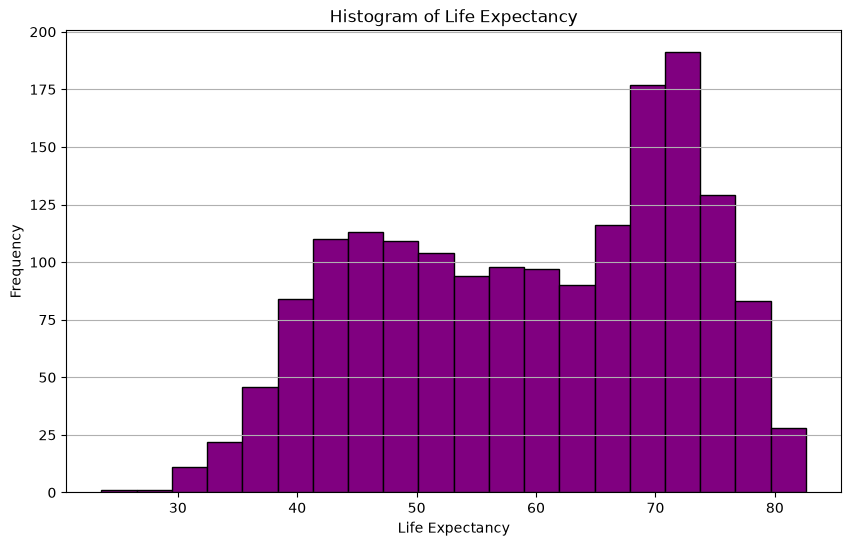

In [17]:
# Inspect the marginal distribution of life expectancy.

plt.figure(figsize=(10, 6))
plt.hist(df['lifeExp'], bins=20, color='purple', edgecolor='black')
plt.title('Histogram of Life Expectancy')
plt.xlabel('Life Expectancy')
plt.ylabel('Frequency')
plt.grid(axis='y')
plt.show()

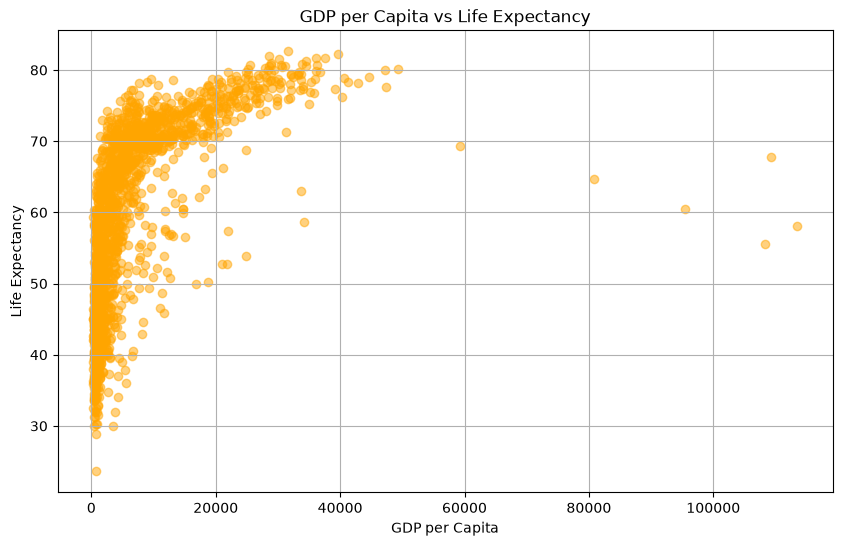

In [18]:
# Compare income and longevity through a scatter plot.

plt.figure(figsize=(10, 6))
plt.scatter(df['gdpPercap'], df['lifeExp'], alpha=0.5, color='orange')
plt.title('GDP per Capita vs Life Expectancy')
plt.xlabel('GDP per Capita')
plt.ylabel('Life Expectancy')
plt.grid(True)
plt.show()

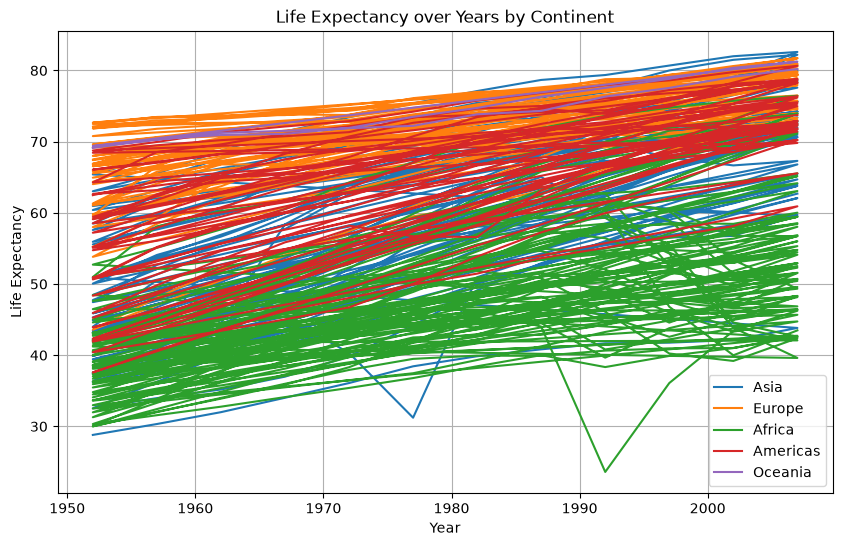

In [19]:
# Trace average life expectancy through time by continent.

plt.figure(figsize=(10, 6))
for continent in df['continent'].unique():
    df_continent = df[df['continent'] == continent]
    plt.plot(df_continent['year'], df_continent['lifeExp'], label=continent)
plt.title('Life Expectancy over Years by Continent')
plt.xlabel('Year')
plt.ylabel('Life Expectancy')
plt.legend()
plt.grid(True)
plt.show()

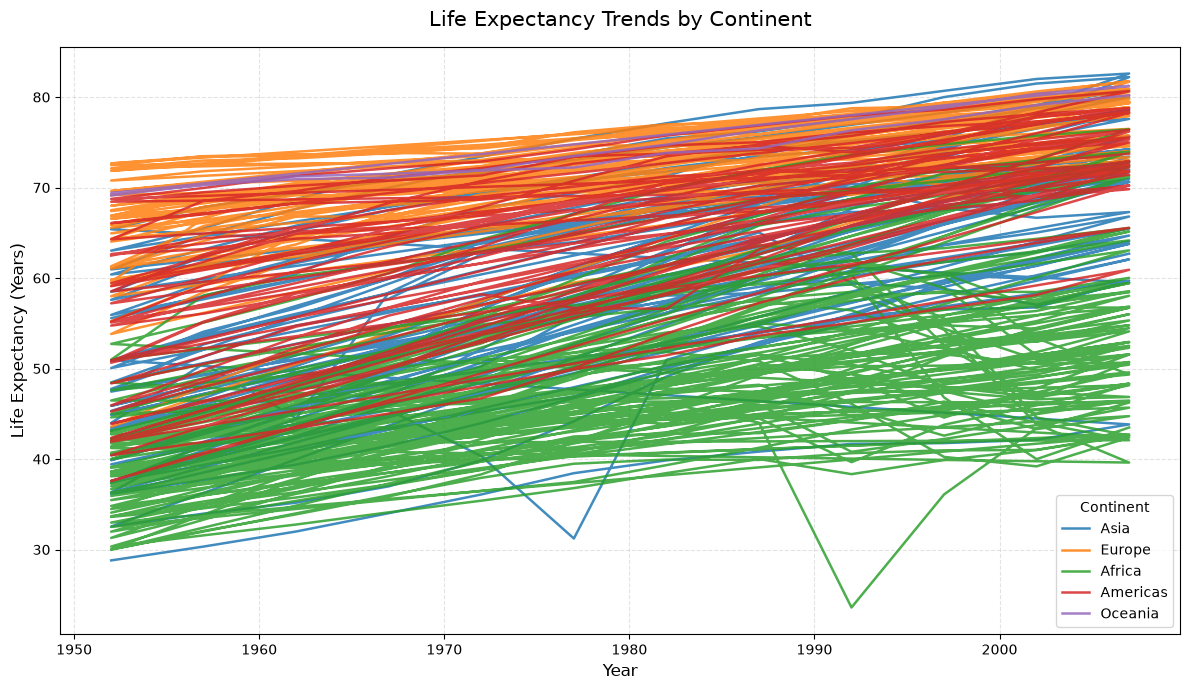

In [21]:
# Build an interactive continent-level timeline.

import matplotlib.pyplot as plt

# Create a figure for comparing life expectancy trends.
fig, ax = plt.subplots(figsize=(12, 7))

# Draw one line for each continent, preserving the
# original observations and their order.
for continent, group in df.groupby('continent', sort=False):

    ax.plot(
        group['year'],
        group['lifeExp'],
        label=continent,
        linewidth=1.8,
        alpha=0.85
    )

# Configure the chart title and axis descriptions.
ax.set_title(
    'Life Expectancy Trends by Continent',
    fontsize=15,
    pad=15
)

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Life Expectancy (Years)', fontsize=12)

# Improve readability with a light background grid.
ax.grid(
    True,
    linestyle='--',
    alpha=0.35
)

# Identify the continents represented in the visualization.
ax.legend(
    title='Continent',
    loc='best',
    frameon=True
)

# Adjust the layout and display the figure.
plt.tight_layout()
plt.show()
